## 01 · Exploratory data analysis and cleaning
We explore train only. The questions we want answered this week:
1. Can we trust the data? (types, hidden missing values, duplicates, impossible values)
2. How imbalanced is churn? (this decides our metrics)
3. Which customers churn, and when? (tenure, contract, price, add-on services)
4. What is it worth? (revenue at risk)
5. Which columns are safe to use as features?

Deeper statistics (confidence intervals, association scores, rule-based baselines, a first tree) wait for the weeks that need them: feature engineering and modelling.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from src.utils.paths import PROCESSED_DIR, RAW_DIR

sns.set_theme(style="whitegrid")
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.3f}'.format)


In [3]:
train_df = pd.read_csv(RAW_DIR / "train.csv")
eval_df = pd.read_csv(RAW_DIR / "eval.csv")


print('train:', train_df.shape, '| eval:', eval_df.shape)


train: (4930, 21) | eval: (1056, 21)


## 1. First look

In [4]:
train_df.head(3)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,6918-UMQCG,Female,0,No,No,5,Yes,No,Fiber optic,No,No,No,No,Yes,No,Month-to-month,No,Electronic check,80.200,384.25,No
1,4140-MUHUG,Female,1,No,No,3,Yes,No,Fiber optic,No,No,Yes,No,Yes,No,Month-to-month,Yes,Electronic check,86.850,220.95,Yes
2,5570-PTWEH,Female,0,Yes,No,3,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Credit card (automatic),75.150,216.75,Yes


In [38]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4930 entries, 0 to 4929
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        4930 non-null   str    
 1   gender            4930 non-null   str    
 2   SeniorCitizen     4930 non-null   int64  
 3   Partner           4930 non-null   str    
 4   Dependents        4930 non-null   str    
 5   tenure            4930 non-null   int64  
 6   PhoneService      4930 non-null   str    
 7   MultipleLines     4930 non-null   str    
 8   InternetService   4930 non-null   str    
 9   OnlineSecurity    4930 non-null   str    
 10  OnlineBackup      4930 non-null   str    
 11  DeviceProtection  4930 non-null   str    
 12  TechSupport       4930 non-null   str    
 13  StreamingTV       4930 non-null   str    
 14  StreamingMovies   4930 non-null   str    
 15  Contract          4930 non-null   str    
 16  PaperlessBilling  4930 non-null   str    
 17  Paymen

In [6]:
train_df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,4930.000,0.161,0.368,0.000,0.000,0.000,0.000,1.000
tenure,4930.000,32.471,24.646,0.000,9.000,29.000,56.000,72.000
MonthlyCharges,4930.000,64.950,30.244,18.400,35.500,70.575,90.050,118.750


In [7]:
train_df.describe(exclude='number').T # type: ignore

,count,unique,top,freq
customerID,4930,4930,6918-UMQCG,1
gender,4930,2,Male,2478
Partner,4930,2,No,2558
Dependents,4930,2,No,3463
PhoneService,4930,2,Yes,4434
MultipleLines,4930,3,No,2347
InternetService,4930,3,Fiber optic,2177
OnlineSecurity,4930,3,No,2439
OnlineBackup,4930,3,No,2142
DeviceProtection,4930,3,No,2140


## 2. Data quality

Never trust a clean-looking info(). We check four things: hidden missing values, duplicates, impossible values, and consistency between columns.

In [26]:
# 2a. Real missing values (NaN)
missing = train_df.isnull().sum()
missing[missing > 0]

Series([], dtype: int64)

In [27]:
# 2b. Hidden missing values: blank strings are NOT counted as NaN by pandas
blank_counts = {C:(train_df[C].astype(str).str.strip() == '').sum() for C in train_df.columns}
{C:n for C,n in blank_counts.items() if n > 0}

{'TotalCharges': np.int64(7)}

## TotalCharges has blank values, which is why pandas read it as text (text) instead of numbers. Before choosing how to fix it, we find out who these customers are.

In [31]:
blank_total = train_df[train_df['TotalCharges'].astype(str).str.strip() == ""]
blank_total[["customerID","tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
42,4075-WKNIU,0,73.350,,No
614,3213-VVOLG,0,25.350,,No
1218,2520-SGTTA,0,20.000,,No
4123,4472-LVYGI,0,52.550,,No
4422,4367-NUYAO,0,25.750,,No
4690,2775-SEFEE,0,61.900,,No
4911,7644-OMVMY,0,19.850,,No


In [32]:
print("Blank TotalCharges rows:", len(blank_total))
print("All of them have tenure == 0:", (blank_total["tenure"] == 0).all())
print("Customers with tenure == 0 in train:", (train_df["tenure"] == 0).sum())

Blank TotalCharges rows: 7
All of them have tenure == 0: True
Customers with tenure == 0 in train: 7


In [33]:
#2c. Check for duplicates
print("fully duplicated rows:", train_df.duplicated().sum())
print("duplicated customerIDs:", train_df["customerID"].duplicated().sum())
print("identical profiles(ignoring ID):", train_df.drop(columns="customerID").duplicated().sum())

fully duplicated rows: 0
duplicated customerIDs: 0
identical profiles(ignoring ID): 9


Identical profiles with different IDs are different customers who happen to have the same plan, so we keep them. We only drop rows that repeat the same CustomerID

In [40]:
# 2d. Impossible values
checks = {
    "tenure < 0": (pd.to_numeric(train_df["tenure"], errors="coerce") < 0).sum(),
    "MonthlyCharges <= 0": (pd.to_numeric(train_df["MonthlyCharges"], errors="coerce") <= 0).sum(),
    "TotalCharges < 0": (pd.to_numeric(train_df["TotalCharges"], errors="coerce") < 0).sum(),
}
checks


{'tenure < 0': np.int64(0),
 'MonthlyCharges <= 0': np.int64(0),
 'TotalCharges < 0': np.int64(0)}

In [41]:
# # 2d. Impossible values
# checks = {
#     "tenure < 0": (train_df["tenure"] < 0).sum(),
#     "MonthlyCharges <= 0": (train_df["MonthlyCharges"] <= 0).sum(),
#     "TotalCharges < 0": (train_df["TotalCharges"] < 0).sum(),
# }
# checks

In [36]:
train_df.nunique().sort_values()

gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
PhoneService           2
PaperlessBilling       2
Churn                  2
MultipleLines          3
TechSupport            3
StreamingTV            3
OnlineBackup           3
DeviceProtection       3
StreamingMovies        3
Contract               3
OnlineSecurity         3
InternetService        3
PaymentMethod          4
tenure                73
MonthlyCharges      1448
TotalCharges        4653
customerID          4930
dtype: int64

In [37]:
cat_cols = [
    c for c in train_df.select_dtypes(exclude="number").columns
    if c != "customerID"
]

for col in cat_cols:
    print(f"{col:18s}", sorted(train_df[col].unique()))

gender             ['Female', 'Male']
Partner            ['No', 'Yes']
Dependents         ['No', 'Yes']
PhoneService       ['No', 'Yes']
MultipleLines      ['No', 'No phone service', 'Yes']
InternetService    ['DSL', 'Fiber optic', 'No']
OnlineSecurity     ['No', 'No internet service', 'Yes']
OnlineBackup       ['No', 'No internet service', 'Yes']
DeviceProtection   ['No', 'No internet service', 'Yes']
TechSupport        ['No', 'No internet service', 'Yes']
StreamingTV        ['No', 'No internet service', 'Yes']
StreamingMovies    ['No', 'No internet service', 'Yes']
Contract           ['Month-to-month', 'One year', 'Two year']
PaperlessBilling   ['No', 'Yes']
PaymentMethod      ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
TotalCharges       [' ', '100.2', '100.25', '100.35', '100.4', '100.8', '100.9', '1001.2', '1001.5', '1003.05', '1004.5', '1004.75', '1005.7', '1006.9', '1007.8', '1007.9', '1008.55', '1008.7', '1009.25', '101.45', '101

Note the values "No internet service" and "No phone service". They carry the same information as the InternetService / PhoneService columns. We keep this in mind for feature engineering (Week 2).

In [44]:
# 2e. Consistency: TotalCharges should be roughly tenure x MonthlyCharges

expected = train_df["tenure"] * train_df["MonthlyCharges"]
total_charges = pd.to_numeric(train_df["TotalCharges"], errors="coerce")
ratio = (total_charges / expected).replace([np.inf, -np.inf], np.nan)
ratio.describe()

count   4923.000
mean       1.000
std        0.051
min        0.689
25%        0.979
50%        1.000
75%        1.019
max        1.531
dtype: float64

In [43]:
# # 2e. Consistency: TotalCharges should be roughly tenure x MonthlyCharges
# expected = train_df["tenure"] * train_df["MonthlyCharges"]
# ratio = (train_df["TotalCharges"] / expected).replace([np.inf, -np.inf], np.nan)

TotalCharges is close to tenure x MonthlyCharges, so it carries little new information. It does hide one useful signal: average price paid over the lifetime vs the current price (a rise in price can trigger churn). We will test that idea in Week 2.

## 3. The target: how imbalanced is churn?

In [48]:
churn_counts = train_df["Churn"].value_counts()
churn_pct = train_df["Churn"].value_counts(normalize=True) * 100

pd.DataFrame({
    "customers": churn_counts,
    "percent": churn_pct.round(1)
})

,customers,percent
Churn,,
No,3622,73.500
Yes,1308,26.500


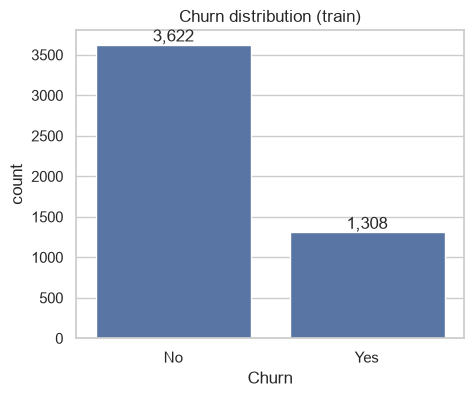

In [49]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=train_df, x="Churn", order=["No", "Yes"], ax=ax)

for bar in ax.patches:
    ax.annotate(
        f"{bar.get_height():,.0f}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom"
    )

ax.set_title("Churn distribution (train)")
plt.show()

In [50]:
majority_accuracy = churn_counts.max() / churn_counts.sum()
print(f"A model that says 'nobody churns' scores {majority_accuracy:.1%} accuracy and 0% recall.")

A model that says 'nobody churns' scores 73.5% accuracy and 0% recall.


Why this matters: a useless model already gets about three quarters accuracy. So we judge models by recall (how many real churners we catch) and precision (how many of our flags were right), and we beat the do-nothing baseline on those, not on accuracy.

In [51]:
# From here on the target is a number: 1 = churned, 0 = stayed
train_df["Churn"] = train_df["Churn"].map({"No": 0, "Yes": 1})
assert train_df["Churn"].notna().all()

base_rate = train_df["Churn"].mean()
status = train_df["Churn"].map({0: "Stayed", 1: "Churned"})  # readable labels for plots
print(f"Overall churn rate: {base_rate:.1%}")

Overall churn rate: 26.5%


## 4. Numeric features

In [54]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
train_df[num_cols] = train_df[num_cols].apply(pd.to_numeric, errors="coerce")

train_df[num_cols].describe().T.assign(skew=train_df[num_cols].skew())

,count,mean,std,min,25%,50%,75%,max,skew
tenure,4930.000,32.471,24.646,0.000,9.000,29.000,56.000,72.000,0.240
MonthlyCharges,4930.000,64.950,30.244,18.400,35.500,70.575,90.050,118.750,-0.220
TotalCharges,4923.000,2305.070,2292.551,18.850,399.800,1389.200,3860.300,8684.800,0.949


In [ ]:
# num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
# train_df[num_cols].describe().T.assign(skew=train_df[num_cols].skew())

## Histograms by churn outcome

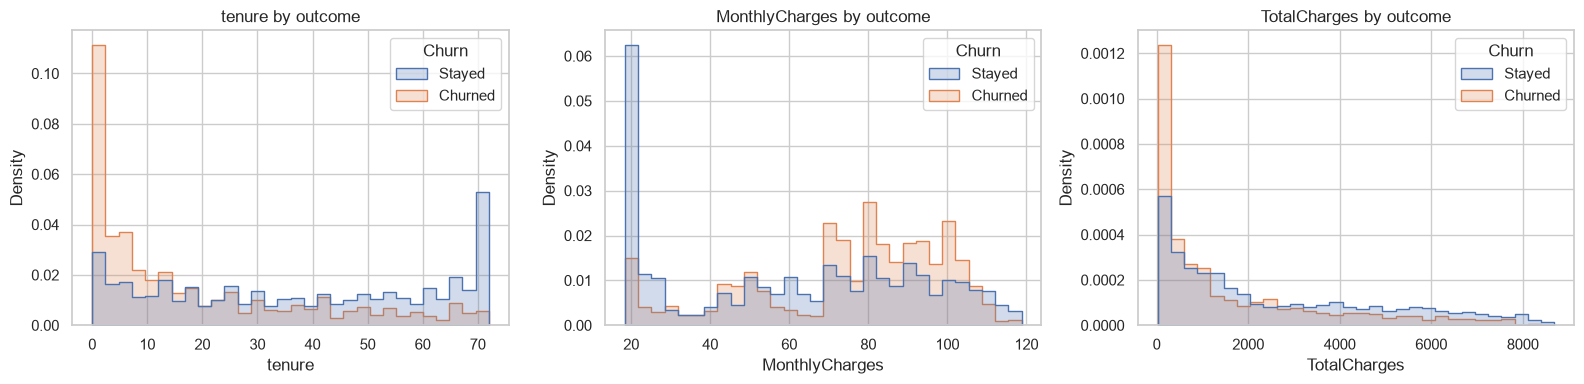

In [55]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, col in zip(axes, num_cols):
    sns.histplot(
        data=train_df,
        x=col,
        hue=status,
        stat="density",
        common_norm=False,
        element="step",
        bins=30,
        ax=ax
    )
    ax.set_title(f"{col} by outcome")

plt.tight_layout()
plt.show()

## Box plots by churn outcome

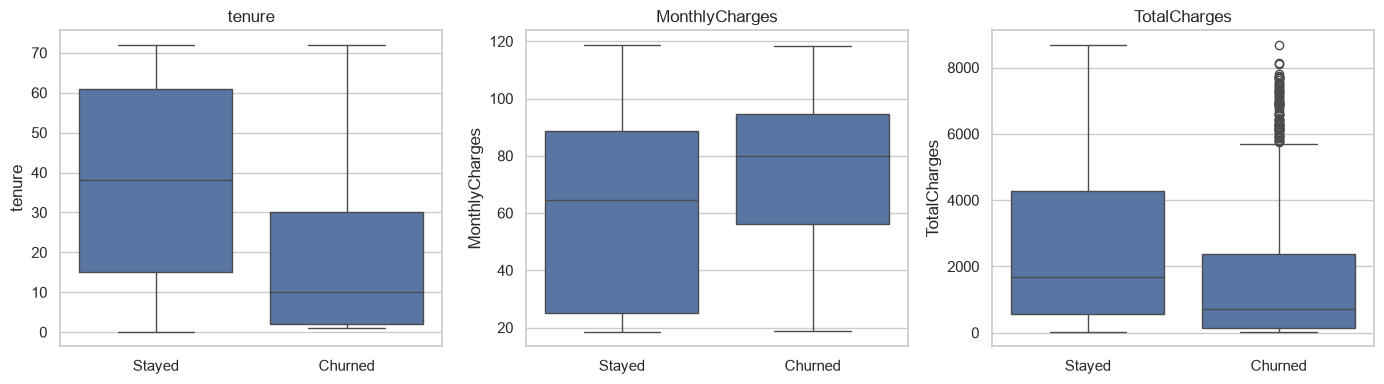

In [56]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, col in zip(axes, num_cols):
    sns.boxplot(
        x=status,
        y=train_df[col],
        order=["Stayed", "Churned"],
        ax=ax
    )
    ax.set_title(col)
    ax.set_xlabel("")

plt.tight_layout()
plt.show()

In [57]:
train_df.groupby("Churn")[num_cols].median()

,tenure,MonthlyCharges,TotalCharges
Churn,,,
0,38.000,64.450,1679.400
1,10.000,80.000,705.075


In [58]:
# Outliers (IQR rule). Do we need to remove any?
for col in num_cols:
    q1, q3 = train_df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = (
        (train_df[col] < q1 - 1.5 * iqr)
        | (train_df[col] > q3 + 1.5 * iqr)
    ).sum()
    print(f"{col:15s} outliers: {n_out}")

tenure          outliers: 0
MonthlyCharges  outliers: 0
TotalCharges    outliers: 0


Finding: churners are newer customers who pay more per month. Unlike the housing prices in the reference project, nothing here looks like a data error, so we do not drop any rows.

Two things to notice in the charts:
- tenure has a spike at 72 months for customers who stayed. The data stops at 72, so these are customers still active when the data was taken, not a special group (this is called censoring).
- MonthlyCharges has a big spike near 20, almost all of it stayers. These are phone-only customers with no internet. The price distribution is really a mix of different products, which is why we look at internet type next to price later.
## 5. When do customers leave? (tenure)
Churn is rarely evenly spread over a customer's life. Let us look at churn rate by tenure.

In [59]:
tenure_band = pd.cut(
    train_df["tenure"],
    bins=[-1, 6, 12, 24, 48, 72],
    labels=["0-6", "7-12", "13-24", "25-48", "49-72"]
)

train_df.groupby(tenure_band, observed=True)["Churn"].agg(
    customers="count",
    churn_rate="mean"
)

,customers,churn_rate
tenure,,
0-6,1030,0.522
7-12,507,0.385
13-24,707,0.273
25-48,1118,0.199
49-72,1568,0.101


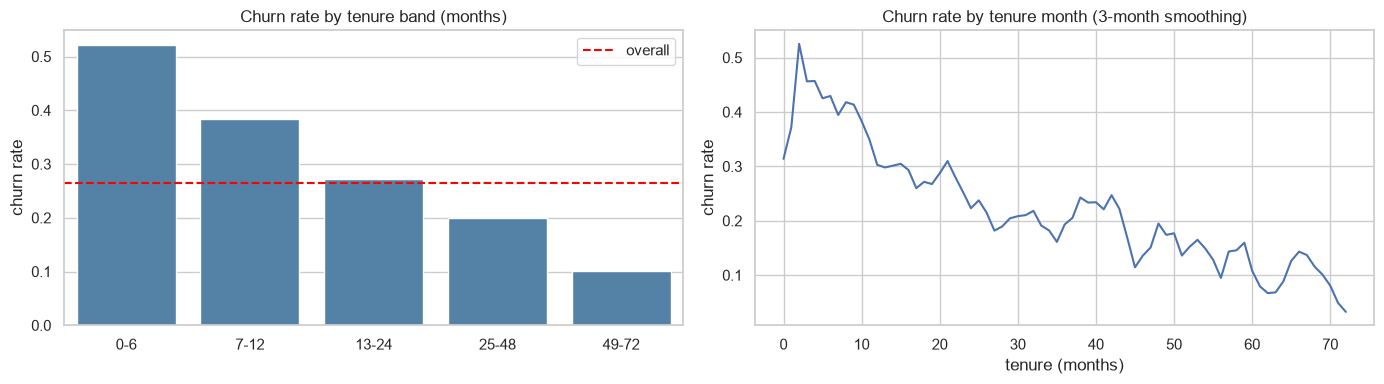

In [60]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

band_rate = train_df.groupby(tenure_band, observed=True)["Churn"].mean()
sns.barplot(
    x=band_rate.index.astype(str),
    y=band_rate.values,
    color="steelblue",
    ax=axes[0]
)
axes[0].axhline(base_rate, ls="--", color="red", label="overall")
axes[0].set(
    title="Churn rate by tenure band (months)",
    xlabel="",
    ylabel="churn rate"
)
axes[0].legend()

month_rate = (
    train_df.groupby("tenure")["Churn"]
    .mean()
    .rolling(3, center=True, min_periods=1)
    .mean()
)
axes[1].plot(month_rate.index, month_rate.values)
axes[1].set(
    title="Churn rate by tenure month (3-month smoothing)",
    xlabel="tenure (months)",
    ylabel="churn rate"
)

plt.tight_layout()
plt.show()